# ERA5 regional mean profiles

Seasonal mean temperature, specific humidity and geopotential profiles over the tropical ocean (20° S–20° N) and the Arctic Ocean (70–85° N), computed from the coarse ARCO-ERA5 store (6-hourly, 128 × 64 grid, 13 pressure levels) and saved with ERA5 short names (`t`, `q`, `z`, `pressure_level`) to `data/era5_region_profiles.nc`. ERA5 access as in {doc}`sea_ice_era5`; how pyRadtran uses ERA5 profiles: {doc}`/guide/atmosphere`. Needs `gcsfs` and network access.

```{note}
The store is chunked as 40 time steps × all levels × the whole globe, so every time step read downloads global fields. Two years (2019–2020) keep the download at a few minutes; extend `YEARS` for a longer climatology.
```

In [1]:
from pathlib import Path

import gcsfs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

YEARS = slice("2019-01-01", "2020-12-31")
REGIONS = {"tropics": slice(-20, 20), "arctic": slice(70, 85)}
OUTPUT_PATH = Path("data/era5_region_profiles.nc")

gcs = gcsfs.GCSFileSystem(token="anon")
era5 = xr.open_zarr(gcs.get_mapper(
    "gs://gcp-public-data-arco-era5/ar/1959-2022-6h-128x64_equiangular_with_poles_conservative.zarr/"
))
era5 = era5[["temperature", "specific_humidity", "geopotential", "sea_surface_temperature"]].sel(time=YEARS)
era5

<xarray.Dataset> Size: 4GB
Dimensions:                  (time: 2924, level: 13, longitude: 128,
                              latitude: 64)
Coordinates:
  * latitude                 (latitude) float64 512B -90.0 -87.14 ... 87.14 90.0
  * level                    (level) int64 104B 50 100 150 200 ... 850 925 1000
  * longitude                (longitude) float64 1kB 0.0 2.812 ... 354.4 357.2
  * time                     (time) datetime64[ns] 23kB 2019-01-01 ... 2020-1...
Data variables:
    temperature              (time, level, longitude, latitude) float32 1GB dask.array<chunksize=(24, 13, 128, 64), meta=np.ndarray>
    specific_humidity        (time, level, longitude, latitude) float32 1GB dask.array<chunksize=(24, 13, 128, 64), meta=np.ndarray>
    geopotential             (time, level, longitude, latitude) float32 1GB dask.array<chunksize=(24, 13, 128, 64), meta=np.ndarray>
    sea_surface_temperature  (time, longitude, latitude) float32 96MB dask.array<chunksize=(24, 128, 64), meta=np.ndarray>

## Area-weighted ocean means

Land points are excluded with the ERA5 sea-surface-temperature mask (SST is undefined over land, defined over sea ice), so no below-ground pressure levels enter the mean. Grid cells are weighted by cos(latitude). Both regions come out of one pass over the data.

In [2]:
ocean = era5["sea_surface_temperature"].isel(time=0).notnull()
weights = np.cos(np.deg2rad(era5.latitude))

profiles = xr.concat(
    [
        era5[["temperature", "specific_humidity", "geopotential"]]
        .sel(latitude=lat).where(ocean.sel(latitude=lat))
        .weighted(weights.sel(latitude=lat)).mean(["latitude", "longitude"])
        for lat in REGIONS.values()
    ],
    dim=xr.DataArray(list(REGIONS), dims="region", name="region"),
)
profiles = profiles.groupby("time.season").mean().load()
profiles

<xarray.Dataset> Size: 3kB
Dimensions:            (season: 4, region: 2, level: 13)
Coordinates:
  * level              (level) int64 104B 50 100 150 200 ... 700 850 925 1000
  * region             (region) <U7 56B 'tropics' 'arctic'
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Data variables:
    temperature        (season, region, level) float64 832B 204.6 ... 268.1
    specific_humidity  (season, region, level) float64 832B 2.783e-06 ... 0.0...
    geopotential       (season, region, level) float64 832B 2.018e+05 ... 797.6

## Save with ERA5 short names

In [3]:
ds_out = profiles.rename(
    {"temperature": "t", "specific_humidity": "q", "geopotential": "z", "level": "pressure_level"}
)
for name, unit in [("t", "K"), ("q", "kg kg-1"), ("z", "m2 s-2"), ("pressure_level", "hPa")]:
    ds_out[name].attrs["units"] = unit
ds_out.attrs["description"] = "ERA5 2019-2020 seasonal, area-weighted ocean-mean profiles"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
ds_out.to_netcdf(OUTPUT_PATH)
ds_out

<xarray.Dataset> Size: 3kB
Dimensions:         (season: 4, region: 2, pressure_level: 13)
Coordinates:
  * pressure_level  (pressure_level) int64 104B 50 100 150 200 ... 850 925 1000
  * region          (region) <U7 56B 'tropics' 'arctic'
  * season          (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Data variables:
    t               (season, region, pressure_level) float64 832B 204.6 ... 2...
    q               (season, region, pressure_level) float64 832B 2.783e-06 ....
    z               (season, region, pressure_level) float64 832B 2.018e+05 ....
Attributes:
    description:  ERA5 2019-2020 seasonal, area-weighted ocean-mean profiles

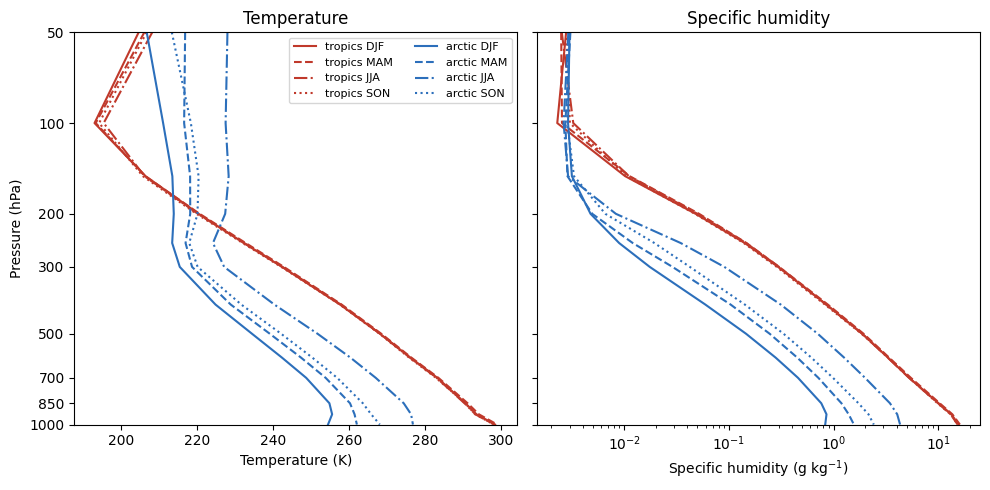

In [4]:
seasons = ["DJF", "MAM", "JJA", "SON"]
styles = dict(zip(seasons, ["-", "--", "-.", ":"]))
colors = {"tropics": "#c0392b", "arctic": "#2c6fbb"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for region, c in colors.items():
    for season in seasons:
        prof = ds_out.sel(region=region, season=season)
        kw = dict(color=c, ls=styles[season], label=f"{region} {season}")
        ax1.plot(prof["t"], prof["pressure_level"], **kw)
        ax2.plot(prof["q"] * 1e3, prof["pressure_level"], **kw)
ax1.set(xlabel="Temperature (K)", ylabel="Pressure (hPa)", yscale="log", ylim=(1000, 50),
        title="Temperature")
ax2.set(xlabel="Specific humidity (g kg$^{-1}$)", xscale="log", title="Specific humidity")
ax1.set_yticks([1000, 850, 700, 500, 300, 200, 100, 50], labels=[1000, 850, 700, 500, 300, 200, 100, 50])
ax1.minorticks_off()
ax1.legend(fontsize=8, ncol=2)
plt.tight_layout()

The tropical profiles barely change with season. The Arctic ones span ≈ 22 K at 1000 hPa between winter (DJF) and summer (JJA), and the winter mean has a weak (≈ 1 K) inversion between 1000 and 925 hPa. In both regions specific humidity falls by a factor of about 50 between 1000 and 300 hPa; the Arctic air holds 4–20 times less water vapour than the tropical air at the surface.

Caveat: two years only, and the 1000 hPa level is a mean over sea-ice and open-ocean points that ERA5 partly fills by extrapolation where the surface pressure is below 1000 hPa.